# Patient cohorts

This tutorial uses a COVID-19 cohort in which some patients were sampled on more than one day. The data has three
levels: patients with their clinical covariates, samples with their collection day, and cells. We split it into these
levels, select at each level, move information between levels, compute sample representations with patpy, and set up
cross validation in which all samples of a patient stay on the same side of a split.

We use the PBMC cohort of [Stephenson et al. (2021)](https://doi.org/10.1038/s41591-021-01329-2), subsampled to
about 500 cells per sample for the pertpy example data. It covers 119 patients with disease status, severity,
outcome, smoking status, sex and the site that collected the blood.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

from donordata import DonorData, read_dd

adata = sc.read(
    "data/stephenson_2021_subsampled.h5ad",
    backup_url="https://scverse-exampledata.s3.eu-west-1.amazonaws.com/pertpy/stephenson_2021_subsampled.h5ad",
)
adata

AnnData object with n_obs × n_vars = 62509 × 16299
    obs: 'Collection_Day', 'Swab_result', 'Status', 'Smoker', 'Status_on_day_collection', 'Status_on_day_collection_summary', 'Days_from_onset', 'Site', 'time_after_LPS', 'Worst_Clinical_Status', 'Outcome', 'patient_id', 'author_cell_type', 'organism', 'sex', 'tissue', 'ethnicity', 'disease', 'assay', 'cell_type', 'dataset_group'
    var: 'gene_id', 'gene_name'
    uns: 'log1p', 'umap'
    obsm: 'X_scVI', 'X_umap'

Ten patients were sampled on more than one day. A sample is a patient on a collection day, so we give every sample
its own identifier. A coarse cell type annotation keeps the plots readable.

In [2]:
adata.obs["sample_id"] = (adata.obs["patient_id"].astype(str) + "_" + adata.obs["Collection_Day"].astype(str)).astype(
    "category"
)

rules = [
    ("mono", "Monocyte"),
    ("Mono", "Monocyte"),
    ("Plasma", "Plasma"),
    ("CD4", "CD4 T"),
    ("Treg", "CD4 T"),
    ("CD8", "CD8 T"),
    ("NKT", "Other lymphoid"),
    ("NK", "NK"),
    ("B_", "B"),
    ("DC", "DC"),
    ("gdT", "Other lymphoid"),
    ("MAIT", "Other lymphoid"),
    ("ILC", "Other lymphoid"),
]
categories = adata.obs["author_cell_type"].cat.categories
coarse = {name: next((value for key, value in rules if key in name), "Other") for name in categories}
adata.obs["cell_type_coarse"] = adata.obs["author_cell_type"].map(coarse).astype("category")
adata.obs["cell_type_coarse"].value_counts()

cell_type_coarse
CD4 T             17397
NK                10027
CD8 T              9792
Monocyte           9453
B                  8124
Other lymphoid     3158
Other              2357
Plasma             1112
DC                 1089
Name: count, dtype: int64

## Three levels in one object

`DonorData.from_anndata` checks every column of `adata.obs`. Columns that take a single value within every patient
move to the patient table `D`, columns that are constant within samples but differ between the samples of a patient
move to the sample table `S`, and everything that varies between cells stays in `C`.

In [3]:
dd = DonorData.from_anndata(adata, donor_id="patient_id", sample_id="sample_id")
dd

╔═ DonorData(n_donors=119, n_samples=129, n_cells=62,509) ═════════════════════╗
║ ┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓ ║
║ ┃                        ┃ S (samples, 1..2 per   ┃ C (cells, 376..1,000   ┃ ║
║ ┃ D (donors)             ┃ donor)                 ┃ per sample)            ┃ ║
║ ┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩ ║
║ │ DataFrame with 119     │ DataFrame with 129     │ View of AnnData object │ ║
║ │ donors × 17 columns    │ samples × 2 columns    │ with n_obs × n_vars =  │ ║
║ │                        │                        │ 62,509 × 16,299        │ ║
║ │     columns:           │     columns:           │     obs: 'patient_id', │ ║
║ │ 'Swab_result',         │ 'patient_id',          │ 'author_cell_type',    │ ║
║ │ 'Status', 'Smoker',    │ 'Collection_Day'       │ 'cell_type',           │ ║
║ │ 'Status_on_day_collec… │                        │ 'sample_id',           │ ║
║ │ 'Status_on_day_collec… │                        │ 'cell_type_coarse'     │ ║
║ │ 'Days_from_onset',     │                        │                        │ ║
║ │ 'Site',                │                        │                        │ ║
║ │ 'time_after_LPS',      │                        │                        │ ║
║ │ 'Worst_Clinical_Statu… │                        │                        │ ║
║ │ 'Outcome', 'organism', │                        │                        │ ║
║ │ 'sex', 'tissue',       │                        │                        │ ║
║ │ 'ethnicity',           │                        │                        │ ║
║ │ 'disease', 'assay',    │                        │                        │ ║
║ │ 'dataset_group'        │                        │                        │ ║
║ │                        │                        │     var: 'gene_id',    │ ║
║ │                        │                        │ 'gene_name'            │ ║
║ │                        │                        │     uns: 'log1p',      │ ║
║ │                        │                        │ 'umap'                 │ ║
║ │                        │                        │     obsm: 'X_scVI',    │ ║
║ │                        │                        │ 'X_umap'               │ ║
║ └────────────────────────┴────────────────────────┴────────────────────────┘ ║
╚═ donor_id='patient_id', sample_id='sample_id' ═══════════════════════════════╝

In [4]:
dd.D.head()

,Swab_result,Status,Smoker,Status_on_day_collection,Status_on_day_collection_summary,Days_from_onset,Site,time_after_LPS,Worst_Clinical_Status,Outcome,organism,sex,tissue,ethnicity,disease,assay,dataset_group
patient_id,,,,,,,,,,,,,,,,,
AP1,Positive,Covid,Smoker,ITU_NIV,Severe,28,Sanger,nan,nan,unknown,Homo sapiens,male,blood,unknown,COVID-19,10x 3' transcription profiling,P
AP2,Positive,Covid,Ex-smoker,ITU_intubated,Critical,47,Sanger,nan,nan,unknown,Homo sapiens,male,blood,unknown,COVID-19,10x 3' transcription profiling,P
AP3,Positive,Covid,Ex-smoker,Ward_O2,Moderate,3,Sanger,nan,nan,unknown,Homo sapiens,male,blood,unknown,COVID-19,10x 3' transcription profiling,P
AP4,Positive,Covid,Smoker,Ward_noO2,Mild,15,Sanger,nan,nan,unknown,Homo sapiens,male,blood,unknown,COVID-19,10x 3' transcription profiling,P
AP5,Positive,Covid,Non-smoker,ITU_NIV,Severe,10,Sanger,nan,nan,unknown,Homo sapiens,female,blood,unknown,COVID-19,10x 3' transcription profiling,P


In [5]:
dd.S.head()

,patient_id,Collection_Day
sample_id,,
AP1_D0,AP1,D0
AP2_D0,AP2,D0
AP3_D0,AP3,D0
AP4_D0,AP4,D0
AP5_D0,AP5,D0


In [6]:
list(dd.C.obs.columns)

['patient_id',
 'author_cell_type',
 'cell_type',
 'sample_id',
 'cell_type_coarse']

Patient covariates are stored once per patient in `D`. Here we add an ordered severity scale. Cells are stored
grouped by sample and samples grouped by patient, so the cells of a unit form a contiguous block of `C`.

In [7]:
severity = ["Healthy", "Asymptomatic", "Mild", "Moderate", "Severe", "Critical"]
dd.D["severity"] = pd.Categorical(dd.D["Status_on_day_collection_summary"], categories=severity, ordered=True)
pd.DataFrame({"patients": dd.D["severity"].value_counts(sort=False)})

,patients
severity,
Healthy,23
Asymptomatic,9
Mild,23
Moderate,30
Severe,13
Critical,15


In [8]:
dd.n_samples_per_donor.value_counts()

n_samples
1    109
2     10
Name: count, dtype: int64

## Selecting at every level

A selection at one level is passed on to the others. Selecting patients selects their samples and cells, selecting
samples drops patients without samples, and selecting cells drops samples and patients without cells.

In [9]:
def sizes(data):
    return {"patients": data.n_donors, "samples": data.n_samples, "cells": data.n_cells}


pd.DataFrame(
    {
        "all": sizes(dd),
        "COVID-19 at Ncl": sizes(dd.filter_donors("Status == 'Covid' and Site == 'Ncl'")),
        "first visit": sizes(dd.filter_samples("Collection_Day == 'D0'")),
        "monocytes": sizes(dd.filter_cells("cell_type_coarse == 'Monocyte'")),
    }
)

,all,COVID-19 at Ncl,first visit,monocytes
patients,119,43,115,112
samples,129,43,115,122
cells,62509,19818,55688,9453


Quality filters are usually defined per sample. Here we keep samples with at least 20 cells of every major cell
type, the requirement of cell type specific pseudobulk and composition analyses. Patients whose samples all fail
leave the cohort with them.

In [10]:
major_types = ["B", "CD4 T", "CD8 T", "Monocyte", "NK"]
qc = dd.filter_donors_by_cells(20, groupby="cell_type_coarse", groups=major_types, level="sample")
sizes(qc)

{'patients': 62, 'samples': 63, 'cells': 30637}

## Information from any level

`get_df` collects variables from any level into one table at the level you ask for. Patient and sample covariates
are repeated for their cells, and cell values are averaged for their samples or patients. Keys can be columns, genes
or matrices in `obsm`, which expand into one column per dimension.

In [11]:
dd.get_df(["severity", "Collection_Day", "cell_type_coarse", "CD14"], level="cell").head()

,severity,Collection_Day,cell_type_coarse,CD14
10_1038_s41591_021_01329_2-S11_GAGTCCGGTTCAGGCC-1,Severe,D0,CD4 T,0.0
10_1038_s41591_021_01329_2-S12_ACTGTCCTCTCGTATT-1,Severe,D0,CD4 T,0.0
10_1038_s41591_021_01329_2-S12_CTCTAATAGTTTCCTT-1,Severe,D0,NK,0.0
10_1038_s41591_021_01329_2-S12_GCATACAGTAATCGTC-1,Severe,D0,CD8 T,0.0
10_1038_s41591_021_01329_2-S12_GACTGCGTCCTTTCGG-1,Severe,D0,NK,0.0


In [12]:
dd.get_df(["severity", "Site", "CD14", "X_scVI"], level="sample").iloc[:5, :7]

,severity,Site,CD14,X_scVI_0,X_scVI_1,X_scVI_2,X_scVI_3
sample_id,,,,,,,
AP1_D0,Severe,Sanger,0.237321,0.150025,0.112920,-0.131538,0.141840
AP2_D0,Critical,Sanger,0.083957,0.026462,-0.045900,-0.096299,-0.114455
AP3_D0,Moderate,Sanger,0.077423,-0.222341,0.007852,-0.069871,0.318170
AP4_D0,Mild,Sanger,0.084559,-0.064465,0.107410,-0.058017,0.124908
AP5_D0,Severe,Sanger,0.177320,-0.158523,-0.045889,-0.228352,0.263155


## Composition per patient and per sample

`composition` counts cell groups per unit and stores the result in `obsm` of that level, where it follows every
later selection. Pooled over the samples of a patient, it shows how blood composition shifts with severity.

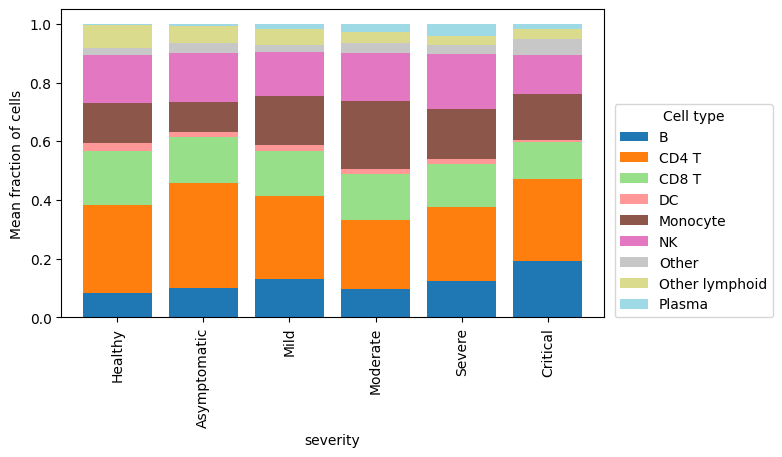

In [13]:
fractions = dd.composition("cell_type_coarse")
mean_by_severity = fractions.groupby(dd.D["severity"], observed=True).mean()
mean_by_severity.plot(kind="bar", stacked=True, figsize=(7, 4), width=0.8, colormap="tab20")
plt.ylabel("Mean fraction of cells")
plt.legend(loc=(1.02, 0), title="Cell type")
plt.show()

Critically ill patients carry more B cells and fewer CD8 T cells in their blood, moderate cases have the most
monocytes, and plasma cells expand in severe disease.

With the sample level, compositions can also be compared between two visits of the same patient. We take the
patients with two samples and compare the centered log ratio of their compositions, the usual transform for
compositional data, between the earlier and the later sample.

In [14]:
repeated = dd.filter_donors(dd.n_samples_per_donor > 1)
clr = repeated.composition("cell_type_coarse", clr=True, level="sample")
visits = repeated.S.assign(day=repeated.S["Collection_Day"].astype(str).str[1:].astype(int))
earlier = visits.sort_values("day").groupby("patient_id", observed=True).head(1).index
later = visits.index.difference(earlier)
change = (
    clr.loc[later].set_axis(visits.loc[later, "patient_id"])
    - clr.loc[earlier].set_axis(visits.loc[earlier, "patient_id"])
).sort_index()
change.round(2)

cell_type_coarse,B,CD4 T,CD8 T,DC,Monocyte,NK,Other,Other lymphoid,Plasma
patient_id,,,,,,,,,
CV0050,0.40,0.11,0.85,-0.22,0.23,1.11,-1.53,0.12,-1.07
CV0062,0.19,0.12,0.09,0.31,0.11,0.11,-0.33,0.41,-0.99
CV0068,-0.13,-0.11,0.62,-0.30,0.16,-0.22,0.39,0.74,-1.15
CV0073,-0.59,-0.39,0.41,0.67,0.29,1.00,-1.08,0.77,-1.09
CV0137,-0.94,0.14,0.78,0.86,2.20,0.40,-1.79,0.46,-2.12
CV0171,0.29,-0.16,0.06,0.88,-0.39,0.22,-0.87,0.32,-0.35
CV0176,-0.41,-0.52,1.06,-0.15,-0.96,0.82,-0.23,0.61,-0.21
CV0178,-1.08,-0.10,0.85,0.81,1.06,0.65,-1.05,0.73,-1.87
CV0201,1.14,-1.54,-0.94,-1.97,-0.74,2.43,0.67,-0.93,1.87


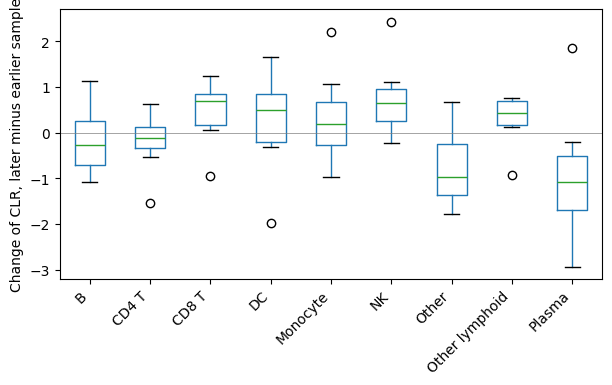

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.5))
change.boxplot(ax=ax, grid=False)
ax.axhline(0, color="grey", lw=0.5)
ax.set_ylabel("Change of CLR, later minus earlier sample")
plt.xticks(rotation=45, ha="right")
plt.show()

Between the earlier and the later sample, plasma cells fall in nine of ten patients while CD8 T and NK cells rise,
as expected when the acute antibody response resolves and lymphocytes recover. One patient, CV0201, moves the other
way.

## Sample representations with patpy

[patpy](https://patpy.readthedocs.io) computes representations of samples from their cells. Given a DonorData with a
sample level, its methods represent the samples, read covariates from the sample and patient tables, and write their
results back into the sample level: the representation and its 2D embedding into `obsm`, the sample distances into
`obsp`. Here we use the centered log ratio transformed composition, a baseline that performed well in the patpy
benchmark, and the scVI latent space averaged over the cells of every sample.

In [16]:
import patpy

composition = patpy.tl.CellGroupComposition(sample_key="sample_id", cell_group_key="cell_type_coarse", apply_clr=True)
composition.prepare_anndata(dd)
composition.calculate_distance_matrix()
composition.embed("MDS")
composition.to_donordata("composition_clr")

dd.aggregate(obsm="X_scVI", key_added="scVI_mean", level="sample")
dd.levels["sample"]

AnnData object with n_obs × n_vars = 129 × 0
    obs: 'patient_id', 'Collection_Day'
    obsm: 'composition_clr', 'X_mds_composition_clr', 'scVI_mean'
    obsp: 'composition_clr_distances'

`pseudobulk` turns a level into an AnnData with one averaged expression profile per unit. It carries the sample
table, the patient covariates and all sample-aligned matrices, so scanpy plotting works on it directly.

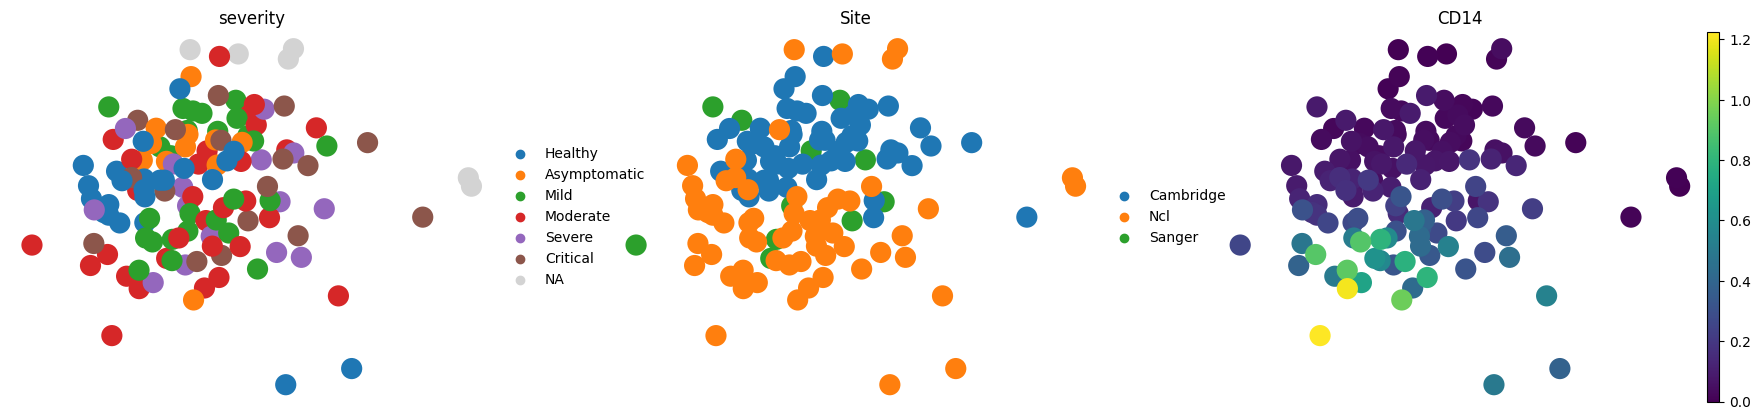

In [17]:
samples = dd.pseudobulk(func="mean", level="sample")
sc.pl.embedding(samples, basis="X_mds_composition_clr", color=["severity", "Site", "CD14"], ncols=3, frameon=False)

The composition embedding separates the collection sites more clearly than the severity groups, and the average CD14
expression of a sample differs between sites as well, which points to differences in sample processing.

Distances follow selections of samples or patients. The distances among COVID-19 samples equal the corresponding
block of the full matrix.

In [18]:
covid = dd.filter_donors("Status == 'Covid'")
full = dd.levels["sample"].obsp["composition_clr_distances"]
block = covid.levels["sample"].obsp["composition_clr_distances"]
positions = dd.S.index.get_indexer(covid.S.index)
np.allclose(block, full[np.ix_(positions, positions)])

True

patpy scores a representation by how well a nearest neighbor predictor recovers sample covariates from the stored
distances. Severity should be predictable, the collection site should not. Covariates of the patient table are
repeated for every sample of the patient.

In [19]:
from patpy.tl.evaluation import knn_prediction_score

known = dd.filter_donors(dd.D["severity"].notna())
known.D["severity_rank"] = known.D["severity"].cat.codes.astype(float)
schema = {
    "relevant": {"severity_rank": "ranking", "Status": "classification"},
    "technical": {"Site": "classification"},
}
knn_prediction_score(known, schema, representations=["composition_clr"], n_neighbors=5)[
    ["covariate", "metric", "score"]
]

,covariate,metric,score
0,severity_rank,spearman_r,0.421991
1,Status,f1_macro_calibrated,0.268331
2,Site,f1_macro_calibrated,0.417647


Severity is recovered with a rank correlation of 0.42. Technical scores are reported as one minus the prediction
score, so that higher means less batch effect, and the 0.42 for the site therefore means that the site is predicted
with a calibrated F1 of 0.58, better than the COVID-19 status. This representation should be corrected for the
collection site before its structure is read biologically.

## Patients, not samples, in train and test

Two samples of the same patient are more alike than samples of different patients, so they should not be split
between training and test data. `kfold` and `train_test_split` draw folds
over patients, so all samples and cells of a patient stay together. Here a logistic regression predicts COVID-19 from
the averaged scVI profile of every sample, with balanced class weights because healthy donors are a minority.

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cohort = dd.filter_donors("Status in ['Covid', 'Healthy']")
cohort.D["Status"] = cohort.D["Status"].cat.remove_unused_categories()

scores = []
for train, test in cohort.kfold(5, stratify="Status", random_state=0):
    assert not set(train.D.index) & set(test.D.index)
    features = {name: part.get_df("scVI_mean", level="sample") for name, part in (("train", train), ("test", test))}
    labels = {
        name: part.get_df("Status", level="sample")["Status"] for name, part in (("train", train), ("test", test))
    }
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
    model.fit(features["train"], labels["train"])
    scores.append(balanced_accuracy_score(labels["test"], model.predict(features["test"])))
print("balanced accuracy per fold:", np.round(scores, 2), "mean:", round(float(np.mean(scores)), 2))

balanced accuracy per fold: [0.89 0.79 0.88 0.86 0.53] mean: 0.79


The spread between folds comes from the small number of healthy patients in every test fold.

Models trained on single cells face the same imbalance one level down. Patients with many cells dominate the loss,
and so does the larger class. `cell_weights` gives every patient the same total weight and, with `by`, every class
of a patient covariate as well.

In [21]:
weights = cohort.cell_weights(by="Status")
cell_status = cohort.get_df("Status", level="cell")["Status"]
pd.DataFrame(
    {"cells": cell_status.value_counts(), "total weight": weights.groupby(cell_status, observed=True).sum().round(0)}
)

,cells,total weight
Status,,
Covid,48083,29937.0
Healthy,11790,29937.0


## Bags of cells for multiple instance learning

Models that look at every cell of a sample, such as attention based multiple instance learning, need one bag of
cells per sample. `MILDataset` reads the bags as contiguous slices of `C`, subsamples or pads them to a fixed size,
takes labels from the sample or patient table, and works with a standard PyTorch `DataLoader`. The supervised methods
of patpy accept a DonorData in the same way.

In [22]:
from torch.utils.data import DataLoader

from donordata.ml import MILDataset, mil_collate_fn

dataset = MILDataset(
    cohort, level="sample", cell_layer="X_scVI", donor_labels_key="Status", n_cells=256, random_state=0
)
loader = DataLoader(dataset, batch_size=8, shuffle=True, collate_fn=mil_collate_fn)
batch = next(iter(loader))
batch["cell_x"].shape, batch["cell_mask"].shape, dataset.encodings["Status"]

(torch.Size([8, 256, 10]), torch.Size([8, 256]), ['Covid', 'Healthy'])

## Pseudobulk profiles for differential expression

With `groupby`, `pseudobulk` returns one profile per sample and cell type. Its `obs` holds the sample table together
with the patient covariates, so a design such as `~ sex + Site + severity` can be written directly, and
`n_cells` and `total_counts` record how much data every profile rests on. This dataset only ships log normalized
expression, so we average here; with raw counts in a layer use `layer="counts"` and `func="sum"`.

In [23]:
profiles = qc.pseudobulk(groupby="cell_type_coarse", func="mean", min_cells=20, level="sample")
profiles.obs[["patient_id", "Collection_Day", "cell_type_coarse", "n_cells", "sex", "Site", "severity"]].head()

,patient_id,Collection_Day,cell_type_coarse,n_cells,sex,Site,severity
AP1_D0_B,AP1,D0,B,23,male,Sanger,Severe
AP1_D0_CD4 T,AP1,D0,CD4 T,243,male,Sanger,Severe
AP1_D0_CD8 T,AP1,D0,CD8 T,48,male,Sanger,Severe
AP1_D0_Monocyte,AP1,D0,Monocyte,92,male,Sanger,Severe
AP1_D0_NK,AP1,D0,NK,43,male,Sanger,Severe


## Adding or removing the patient level

Cohorts are often shared with one row per sample. `nest` adds the patient level to such an object, moving the
columns that are constant within patients into the patient table. `flatten` goes the other way and makes the samples
the units, with patient covariates repeated for every sample.

In [24]:
by_sample = DonorData.from_anndata(adata, donor_id="sample_id")
nested = by_sample.nest("patient_id")
flat = nested.flatten()
for name, data in [("by sample", by_sample), ("nested", nested), ("flattened", flat)]:
    print(f"{name:10} levels {data.level_names}, donor_id={data.donor_id!r}, sample_id={data.sample_id!r}")

by sample  levels ('donor', 'cell'), donor_id='sample_id', sample_id=None
nested     levels ('donor', 'sample', 'cell'), donor_id='patient_id', sample_id='sample_id'
flattened  levels ('donor', 'cell'), donor_id='sample_id', sample_id=None


## Cells in the context of their patient

`to_anndata` attaches sample and patient covariates to every cell and shares all matrices with `C`, for example for
cell level plots with tools that work on a single AnnData.

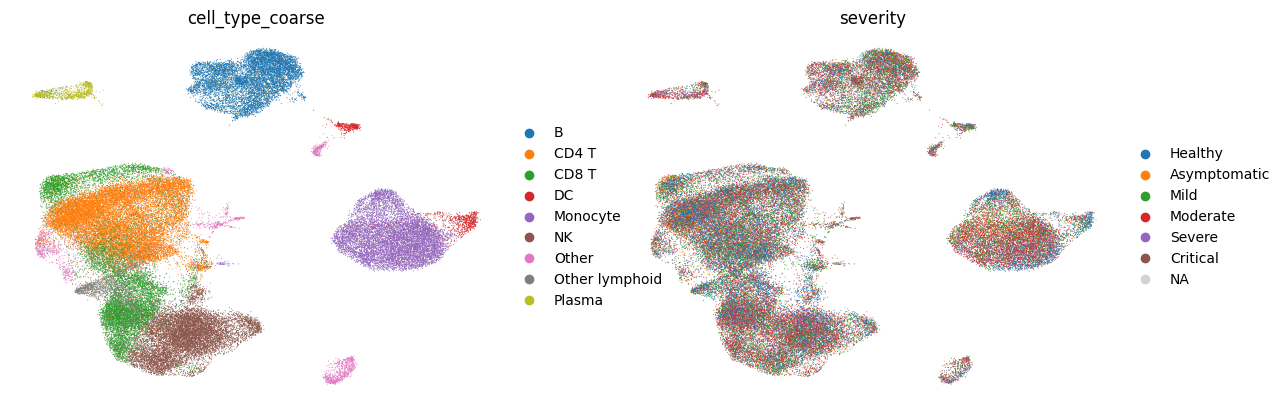

In [25]:
cells = dd.to_anndata(columns=["severity", "Collection_Day"])
sc.pl.umap(cells, color=["cell_type_coarse", "severity"], frameon=False, ncols=2)

## Saving

Patients, samples, cells and every matrix aligned to them are written to a single file.

In [26]:
dd.write_dd("data/stephenson.dd.h5")
read_dd("data/stephenson.dd.h5")

╔═ DonorData(n_donors=119, n_samples=129, n_cells=62,509) ═════════════════════╗
║ ┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓ ║
║ ┃                        ┃ S (samples, 1..2 per   ┃ C (cells, 376..1,000   ┃ ║
║ ┃ D (donors)             ┃ donor)                 ┃ per sample)            ┃ ║
║ ┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩ ║
║ │ DataFrame with 119     │ DataFrame with 129     │ AnnData object with    │ ║
║ │ donors × 18 columns    │ samples × 2 columns    │ n_obs × n_vars =       │ ║
║ │                        │                        │ 62,509 × 16,299        │ ║
║ │     columns:           │     columns:           │     obs: 'patient_id', │ ║
║ │ 'Swab_result',         │ 'patient_id',          │ 'author_cell_type',    │ ║
║ │ 'Status', 'Smoker',    │ 'Collection_Day'       │ 'cell_type',           │ ║
║ │ 'Status_on_day_collec… │                        │ 'sample_id',           │ ║
║ │ 'Status_on_day_collec… │                        │ 'cell_type_coarse'     │ ║
║ │ 'Days_from_onset',     │                        │                        │ ║
║ │ 'Site',                │                        │                        │ ║
║ │ 'time_after_LPS',      │                        │                        │ ║
║ │ 'Worst_Clinical_Statu… │                        │                        │ ║
║ │ 'Outcome', 'organism', │                        │                        │ ║
║ │ 'sex', 'tissue',       │                        │                        │ ║
║ │ 'ethnicity',           │                        │                        │ ║
║ │ 'disease', 'assay',    │                        │                        │ ║
║ │ 'dataset_group',       │                        │                        │ ║
║ │ 'severity'             │                        │                        │ ║
║ │     obsm:              │     obsm:              │     var: 'gene_id',    │ ║
║ │ 'cell_type_coarse_fra… │ 'X_mds_composition_cl… │ 'gene_name'            │ ║
║ │                        │ 'composition_clr',     │                        │ ║
║ │                        │ 'scVI_mean'            │                        │ ║
║ │                        │     obsp:              │     uns:               │ ║
║ │                        │ 'composition_clr_dist… │ 'composition_paramete… │ ║
║ │                        │                        │ 'log1p', 'umap'        │ ║
║ │                        │                        │     obsm: 'X_scVI',    │ ║
║ │                        │                        │ 'X_umap'               │ ║
║ └────────────────────────┴────────────────────────┴────────────────────────┘ ║
╚═ donor_id='patient_id', sample_id='sample_id' ═══════════════════════════════╝